In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

# --- 0. CONFIGURAÇÃO DE ESTILO (Mantendo a sua original) ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 24,
        "axes.labelsize" : 24,
        "legend.fontsize" : 20,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 20,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 20,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Aplicar Config
%matplotlib widget
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

--> Loading LH_0_452Halos_FullSpectra.pkl...
--> Raio alvo: 0.5 R200 | Raio mais próximo encontrado: 0.55 R200
--> Processando Bin 10.0-12.0: 3624 linhas (skewers).
--> Processando Bin 12.0-13.0: 1380 linhas (skewers).
--> Processando Bin 13.0-15.0: 396 linhas (skewers).
--> Figura salva em: Mass_Binned_Spectra.pdf


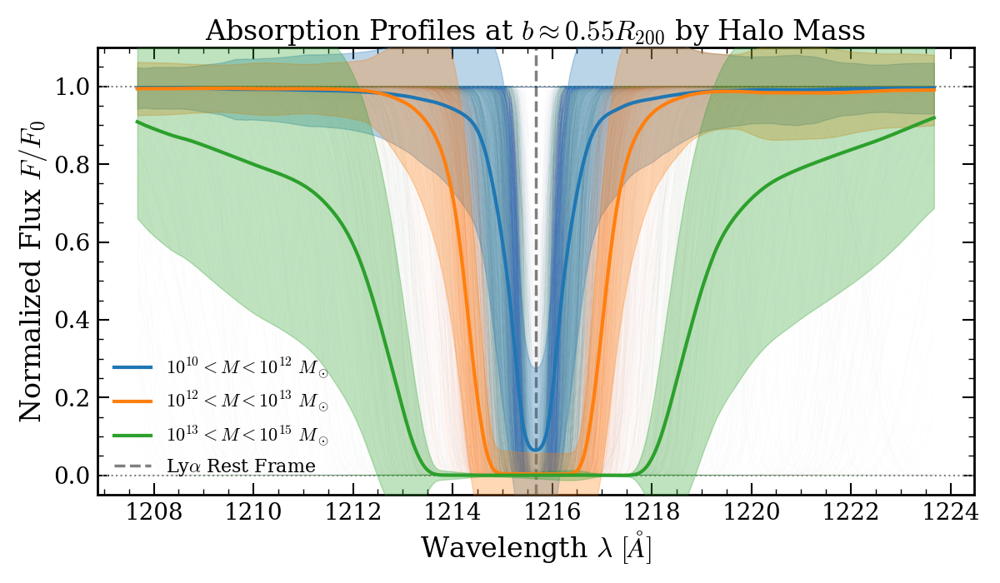

In [3]:

# --- 1. CONFIGURAÇÃO DOS PARÂMETROS ---
PKL_FILE = "LH_0_452Halos_FullSpectra.pkl" 
H_HUBBLE = 0.6774 

# Parâmetros solicitados pelo co-orientador
TARGET_RADIUS_R200 = 0.5  # O "fixed impact parameter" (ex: 0.5 R200)

# Definição dos Bins de Massa (log10 Msun)
# Formato: [(min, max), (min, max), ...]
MASS_BINS = [
    #(9.0, 10.0),
    (10.0, 12.0),
    #(11.0, 12.0), 
    (12.0, 13.0),
    (13.0, 15.0),
]

# Cores para cada bin (certifique-se de ter cores suficientes para os bins)
BIN_COLORS = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'] 
# Labels para a legenda
BIN_LABELS = [
    r'$10^{10} < M < 10^{12} \ M_\odot$',
    #r'$10^{11} < M < 10^{12} \ M_\odot$',
    r'$10^{12} < M < 10^{13} \ M_\odot$',
    r'$10^{13} < M < 10^{15} \ M_\odot$',
]

# --- 2. CARREGAMENTO E PREPARAÇÃO DOS DADOS ---
if not os.path.exists(PKL_FILE):
    print(f"ERRO: Ficheiro {PKL_FILE} não encontrado.")
else:
    print(f"--> Loading {PKL_FILE}...")
    df_all = pd.read_pickle(PKL_FILE)

    # Calcular a massa em log10 (Msun) para filtragem
    # Nota: halo_mass original vem em 10^10 Msun/h, precisamos converter
    # M_sun = (halo_mass * 1e10) / h
    df_all['log_mass_msun'] = np.log10((df_all['halo_mass'] * 1e10) / H_HUBBLE)

    # Encontrar o raio disponível mais próximo do solicitado
    available_radii = np.sort(df_all['r_multiplier'].unique())
    closest_r = available_radii[np.abs(available_radii - TARGET_RADIUS_R200).argmin()]
    print(f"--> Raio alvo: {TARGET_RADIUS_R200} R200 | Raio mais próximo encontrado: {closest_r:.2f} R200")

    # Filtrar apenas pelo raio de interesse (reduz o tamanho do DF)
    df_radius = df_all[df_all['r_multiplier'] == closest_r].copy()

    # --- 3. PLOTTING ---
    fig, ax = plt.subplots(figsize=(12, 7))

    # Grid comum para interpolação (centrado em Ly-alpha 1215.67)
    wave_grid = np.linspace(1215.67 - 8, 1215.67 + 8, 500)

    # Iterar sobre os bins de massa
    for i, (m_min, m_max) in enumerate(MASS_BINS):
        color = BIN_COLORS[i % len(BIN_COLORS)]
        label = BIN_LABELS[i] if i < len(BIN_LABELS) else f"{m_min}-{m_max}"

        # Filtrar o DataFrame para este bin de massa
        mask = (df_radius['log_mass_msun'] >= m_min) & (df_radius['log_mass_msun'] < m_max)
        df_bin = df_radius[mask]

        if df_bin.empty:
            print(f"--> Aviso: Bin {m_min}-{m_max} está vazio.")
            continue
        
        print(f"--> Processando Bin {m_min}-{m_max}: {len(df_bin)} linhas (skewers).")

        # Coletar e interpolar os fluxos
        flux_matrix = []
        
        # Plotar as linhas individuais (Thin lines in background)
        # Para evitar pesar muito o plot se houver milhares de linhas, 
        # podemos usar um 'sample' ou alpha muito baixo.
        for _, row in df_bin.iterrows():
            w = row['wave']
            f = row['flux']
            
            # Interpolação para garantir que todas as linhas tenham o mesmo x-axis
            f_interp = np.interp(wave_grid, w, f)
            flux_matrix.append(f_interp)
            
            # Plot individual (fundo)
            ax.plot(wave_grid, f_interp, color=color, alpha=0.01, lw=0.5, zorder=1)

        # Estatísticas (Mean e Std)
        flux_matrix = np.array(flux_matrix)
        mean_flux = np.nanmean(flux_matrix, axis=0)
        std_flux = np.nanstd(flux_matrix, axis=0)

        # Plotar a média (Thick line)
        ax.plot(wave_grid, mean_flux, color=color, lw=3.0, alpha=1.0, label=label, zorder=10)
        
        # Plotar a sombra (Std deviation)
        ax.fill_between(wave_grid, mean_flux - std_flux, mean_flux + std_flux, 
                        color=color, alpha=0.3, zorder=5)

    # --- 4. FORMATAÇÃO FINAL ---
    ax.axhline(1.0, color='gray', linestyle=':', lw=1.5)
    ax.axhline(0.0, color='gray', linestyle=':', lw=1.5)
    ax.axvline(1215.67, color='black', linestyle='--', alpha=0.5, label=r'Ly$\alpha$ Rest Frame')

    ax.set_ylim(-0.05, 1.1)
    ax.set_xlabel(r'Wavelength $\lambda\ [\AA]$')
    ax.set_ylabel(r'Normalized Flux $F/F_0$')
    
    # Título Informativo
    ax.set_title(f"Absorption Profiles at $b \\approx {closest_r:.2f} R_{{200}}$ by Halo Mass")

    ax.legend(loc='lower left', frameon=False, fontsize=16)

    plt.tight_layout()
    
    # Salvar
    output_img = "Mass_Binned_Spectra.pdf"
    plt.savefig(output_img, bbox_inches='tight', dpi=300)
    print(f"--> Figura salva em: {output_img}")
    
    plt.show()

--> Loading LH_0_452Halos_FullSpectra.pkl...
--> Mass range: 9.83 to 15.03 log10(Msun)

--- Contagem de Halos por Bin de Massa ---
bin 1 (massas entre 9.83 e 11.13) -- 50 halos
bin 2 (massas entre 11.13 e 12.43) -- 341 halos
bin 3 (massas entre 12.43 e 13.73) -- 51 halos
bin 4 (massas entre 13.73 e 15.03) -- 9 halos
------------------------------------------

--> Mass range: 9.83 to 15.03 log10(Msun)
--> Raios encontrados: [0.1        0.23403473 0.54772256 1.28186102 3.        ]


/tmp/ipykernel_3339920/3220893181.py:120: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('plasma')


--> Figura salva em: Mass_Binned_Spectra_16Bins_AllRadii.pdf


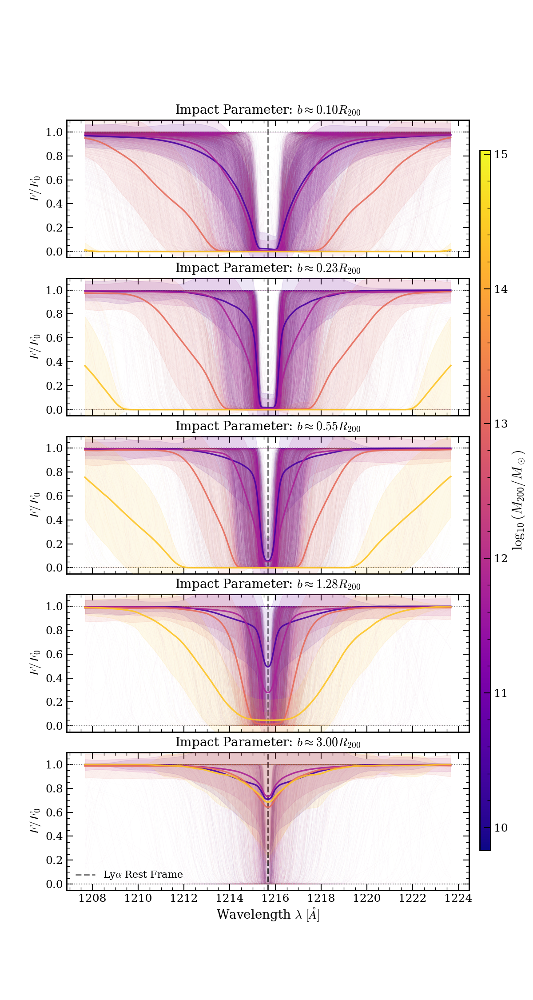

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import os

# --- 0. CONFIGURAÇÃO DE ESTILO ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 20,
        "axes.labelsize" : 20,
        "legend.fontsize" : 16,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 18,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 18,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Aplicar Config
# %matplotlib widget  # Descomente se estiver usando no Jupyter interativo
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- 1. CONFIGURAÇÃO DOS PARÂMETROS ---
PKL_FILE = "LH_0_452Halos_FullSpectra.pkl" # Ajuste para o seu arquivo real
H_HUBBLE = 0.6774 
NUM_BINS = 4

# --- 2. CARREGAMENTO E PREPARAÇÃO DOS DADOS ---
if not os.path.exists(PKL_FILE):
    print(f"ERRO: Ficheiro {PKL_FILE} não encontrado.")
else:
    print(f"--> Loading {PKL_FILE}...")
    df_all = pd.read_pickle(PKL_FILE)

    # 2.1 Calcular a massa em log10 (Msun)
    df_all['log_mass_msun'] = np.log10((df_all['halo_mass'] * 1e10) / H_HUBBLE)

    # 2.2 Definir os 16 Bins de Massa Dinamicamente
    min_mass = df_all['log_mass_msun'].min()
    max_mass = df_all['log_mass_msun'].max()
    mass_edges = np.linspace(min_mass, max_mass, NUM_BINS + 1)
    
    print(f"--> Mass range: {min_mass:.2f} to {max_mass:.2f} log10(Msun)")

    # ==========================================
    # --- RESUMO DE HALOS POR BIN (GLOBAL) ---
    # ==========================================
    print("\n--- Contagem de Halos por Bin de Massa ---")
    for i in range(NUM_BINS):
        m_min = mass_edges[i]
        m_max = mass_edges[i+1]
        
        # Filtra o DataFrame inteiro (que contém todos os raios)
        mask_global = (df_all['log_mass_msun'] >= m_min) & (df_all['log_mass_msun'] < m_max)
        df_bin_global = df_all[mask_global]
        
        # Conta halos únicos (usando a massa como identificador)
        num_halos = df_bin_global['halo_mass'].nunique()
        
        # NOVO FORMATO DE PRINT
        print(f"bin {i+1} (massas entre {m_min:.2f} e {m_max:.2f}) -- {num_halos} halos")
    print("------------------------------------------\n")
    # ==========================================

    # 2.3 Identificar os Raios (Impact Parameters)
    available_radii = np.sort(df_all['r_multiplier'].unique())
    
    print(f"--> Mass range: {min_mass:.2f} to {max_mass:.2f} log10(Msun)")

    # 2.3 Identificar os Raios (Impact Parameters)
    available_radii = np.sort(df_all['r_multiplier'].unique())
    print(f"--> Raios encontrados: {available_radii}")

    # 2.4 Configuração do Mapa de Cores (Colormap)
    # Usando 'plasma' ou 'viridis' para transição de massas
    cmap = cm.get_cmap('plasma') 
    norm = mcolors.Normalize(vmin=min_mass, vmax=max_mass)

    # --- 3. PLOTTING (5 Painéis) ---
    # Cria uma figura grande com 5 linhas e 1 coluna
    fig, axes = plt.subplots(len(available_radii), 1, figsize=(12, 4.5 * len(available_radii)), sharex=True)
    
    # Grid comum para interpolação
    wave_grid = np.linspace(1215.67 - 8, 1215.67 + 8, 500)

    for ax_idx, r_target in enumerate(available_radii):
        ax = axes[ax_idx]
        df_radius = df_all[df_all['r_multiplier'] == r_target].copy()
        
        # Título do subplot
        ax.set_title(f"Impact Parameter: $b \\approx {r_target:.2f} R_{{200}}$", pad=10)

        # Iterar sobre os 16 bins de massa
        for i in range(NUM_BINS):
            m_min = mass_edges[i]
            m_max = mass_edges[i+1]
            mid_mass = (m_min + m_max) / 2.0
            
            # Cor correspondente à massa média do bin
            color = cmap(norm(mid_mass))

            # Filtrar o DataFrame para este bin
            mask = (df_radius['log_mass_msun'] >= m_min) & (df_radius['log_mass_msun'] < m_max)
            df_bin = df_radius[mask]

            if df_bin.empty:
                continue

            flux_matrix = []
            
            # PLOT INDIVIDUAL (Linhas Finas)
            # Alpha bem baixo (0.02) pois teremos muitas linhas
            for _, row in df_bin.iterrows():
                w = row['wave']
                f = row['flux']
                f_interp = np.interp(wave_grid, w, f)
                flux_matrix.append(f_interp)
                
                # rasterized=True evita que o PDF fique com 100MB por causa das milhares de linhas
                ax.plot(wave_grid, f_interp, color=color, alpha=0.02, lw=0.5, zorder=1, rasterized=True)

            # ESTATÍSTICA (Mean e Std)
            flux_matrix = np.array(flux_matrix)
            mean_flux = np.nanmean(flux_matrix, axis=0)
            std_flux = np.nanstd(flux_matrix, axis=0)

            # PLOT MÉDIA
            ax.plot(wave_grid, mean_flux, color=color, lw=2.5, alpha=0.9, zorder=10)
            
            # PLOT SOMBRA (Desvio Padrão) - Opcional, pode poluir com 16 bins. 
            # Se ficar confuso, troque alpha=0.1 ou comente a linha abaixo.
            ax.fill_between(wave_grid, mean_flux - std_flux, mean_flux + std_flux, 
                            color=color, alpha=0.1, zorder=5)

        # Linhas de referência no painel
        ax.axhline(1.0, color='gray', linestyle=':', lw=1.5)
        ax.axhline(0.0, color='gray', linestyle=':', lw=1.5)
        ax.axvline(1215.67, color='black', linestyle='--', alpha=0.5)

        ax.set_ylim(-0.05, 1.1)
        ax.set_ylabel(r'$F/F_0$')

    # Ajuste do eixo X (aparece apenas no último plot)
    axes[-1].set_xlabel(r'Wavelength $\lambda\ [\AA]$')
    axes[-1].axvline(1215.67, color='black', linestyle='--', alpha=0.5, label=r'Ly$\alpha$ Rest Frame')
    axes[-1].legend(loc='lower left', frameon=False)

    # --- 4. COLORBAR GLOBAL ---
    # Adicionar uma colorbar à direita da figura para indicar as massas
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    # Espaço para a colorbar: ajusta os painéis para dar 10% de folga na direita
    fig.subplots_adjust(right=0.88, hspace=0.15) 
    cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7]) # [left, bottom, width, height]
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label(r'$\log_{10}(M_{200} / M_\odot)$', fontsize=22)
    cbar.ax.tick_params(labelsize=18)

    # Salvar
    output_img = "Mass_Binned_Spectra_16Bins_AllRadii.pdf"
    plt.savefig(output_img, bbox_inches='tight', dpi=300)
    print(f"--> Figura salva em: {output_img}")
    
    plt.show()

--> Loading Fiducial_452Halos_FullSpectra.pkl...
--> Mass range: 10.59 to 15.02 log10(Msun)

--- Contagem de Halos por Bin de Massa ---
bin 1 (massas entre 10.59 e 11.70) -- 232 halos
bin 2 (massas entre 11.70 e 12.80) -- 182 halos
bin 3 (massas entre 12.80 e 13.91) -- 30 halos
bin 4 (massas entre 13.91 e 15.02) -- 7 halos
------------------------------------------

--> Mass range: 10.59 to 15.02 log10(Msun)
--> Raios encontrados: [0.1        0.23403473 0.54772256 1.28186102 3.        ]


/tmp/ipykernel_3339920/658191558.py:120: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('plasma')


--> Figura salva em: Mass_Binned_Spectra_16Bins_AllRadii.pdf


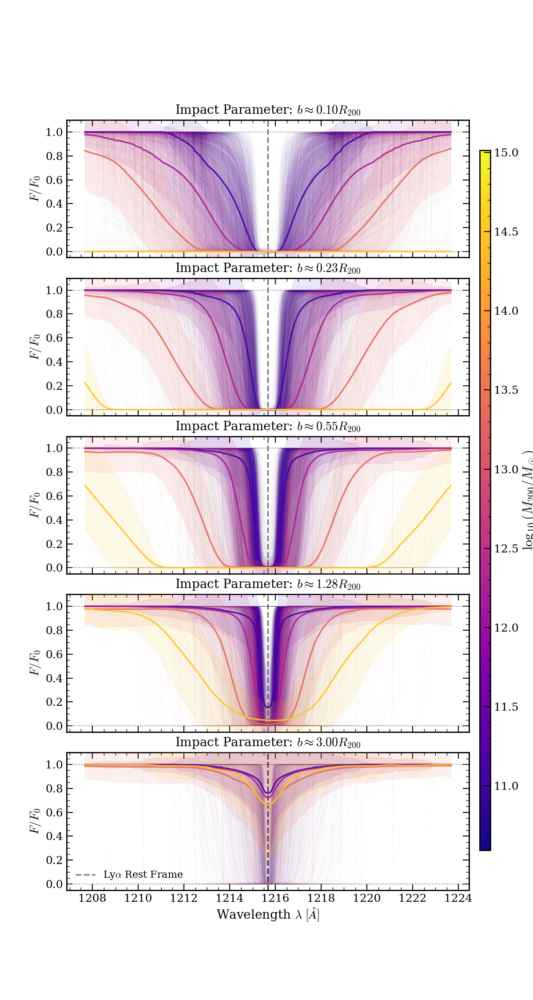

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import os

# --- 0. CONFIGURAÇÃO DE ESTILO ---
def matplotlib_default_config():
    font = {
        'family' : 'serif',
        'weight' : 'normal',
        'size'   : 14
    }
    rcnew = {
        "mathtext.fontset" : "cm", 
        "text.usetex": False,
        'figure.frameon': True,
        'axes.linewidth': 2.,
        "axes.titlesize" : 20,
        "axes.labelsize" : 20,
        "legend.fontsize" : 16,
        'legend.fancybox': True,
        'lines.linewidth': 2.5,
        'xtick.alignment': 'center',
        'xtick.bottom': True,
        'xtick.color': 'black',
        'xtick.direction': 'in',
        'xtick.labelbottom': True,
        'xtick.labelsize': 18,
        'xtick.major.bottom': True,
        'xtick.major.pad': 6.0,
        'xtick.major.size': 10.0,
        'xtick.major.width': 1.5,
        'xtick.minor.bottom': True,
        'xtick.minor.pad': 3.4,
        'xtick.minor.size': 5.0,
        'xtick.minor.visible': True,
        'xtick.minor.width': 1.0,
        'xtick.top': True,
        'ytick.alignment': 'center_baseline',
        'ytick.color': 'black',
        'ytick.direction': 'in',
        'ytick.labelleft': True,
        'ytick.labelsize': 18,
        'ytick.left': True,
        'ytick.major.left': True,
        'ytick.major.pad': 6.0,
        'ytick.major.size': 10.0,
        'ytick.major.width': 1.5,
        'ytick.minor.left': True,
        'ytick.minor.pad': 3.4,
        'ytick.minor.right': True,
        'ytick.minor.size': 5.0,
        'ytick.minor.visible': True,
        'ytick.minor.width': 1.0,
        'ytick.right': True
    }
    return font, rcnew

# Aplicar Config
# %matplotlib widget  # Descomente se estiver usando no Jupyter interativo
font, rcnew = matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)

# --- 1. CONFIGURAÇÃO DOS PARÂMETROS ---
PKL_FILE = "Fiducial_452Halos_FullSpectra.pkl" # Ajuste para o seu arquivo real
H_HUBBLE = 0.6774 
NUM_BINS = 4

# --- 2. CARREGAMENTO E PREPARAÇÃO DOS DADOS ---
if not os.path.exists(PKL_FILE):
    print(f"ERRO: Ficheiro {PKL_FILE} não encontrado.")
else:
    print(f"--> Loading {PKL_FILE}...")
    df_all = pd.read_pickle(PKL_FILE)

    # 2.1 Calcular a massa em log10 (Msun)
    df_all['log_mass_msun'] = np.log10((df_all['halo_mass'] * 1e10) / H_HUBBLE)

    # 2.2 Definir os 16 Bins de Massa Dinamicamente
    min_mass = df_all['log_mass_msun'].min()
    max_mass = df_all['log_mass_msun'].max()
    mass_edges = np.linspace(min_mass, max_mass, NUM_BINS + 1)
    
    print(f"--> Mass range: {min_mass:.2f} to {max_mass:.2f} log10(Msun)")

    # ==========================================
    # --- RESUMO DE HALOS POR BIN (GLOBAL) ---
    # ==========================================
    print("\n--- Contagem de Halos por Bin de Massa ---")
    for i in range(NUM_BINS):
        m_min = mass_edges[i]
        m_max = mass_edges[i+1]
        
        # Filtra o DataFrame inteiro (que contém todos os raios)
        mask_global = (df_all['log_mass_msun'] >= m_min) & (df_all['log_mass_msun'] < m_max)
        df_bin_global = df_all[mask_global]
        
        # Conta halos únicos (usando a massa como identificador)
        num_halos = df_bin_global['halo_mass'].nunique()
        
        # NOVO FORMATO DE PRINT
        print(f"bin {i+1} (massas entre {m_min:.2f} e {m_max:.2f}) -- {num_halos} halos")
    print("------------------------------------------\n")
    # ==========================================

    # 2.3 Identificar os Raios (Impact Parameters)
    available_radii = np.sort(df_all['r_multiplier'].unique())
    
    print(f"--> Mass range: {min_mass:.2f} to {max_mass:.2f} log10(Msun)")

    # 2.3 Identificar os Raios (Impact Parameters)
    available_radii = np.sort(df_all['r_multiplier'].unique())
    print(f"--> Raios encontrados: {available_radii}")

    # 2.4 Configuração do Mapa de Cores (Colormap)
    # Usando 'plasma' ou 'viridis' para transição de massas
    cmap = cm.get_cmap('plasma') 
    norm = mcolors.Normalize(vmin=min_mass, vmax=max_mass)

    # --- 3. PLOTTING (5 Painéis) ---
    # Cria uma figura grande com 5 linhas e 1 coluna
    fig, axes = plt.subplots(len(available_radii), 1, figsize=(12, 4.5 * len(available_radii)), sharex=True)
    
    # Grid comum para interpolação
    wave_grid = np.linspace(1215.67 - 8, 1215.67 + 8, 500)

    for ax_idx, r_target in enumerate(available_radii):
        ax = axes[ax_idx]
        df_radius = df_all[df_all['r_multiplier'] == r_target].copy()
        
        # Título do subplot
        ax.set_title(f"Impact Parameter: $b \\approx {r_target:.2f} R_{{200}}$", pad=10)

        # Iterar sobre os 16 bins de massa
        for i in range(NUM_BINS):
            m_min = mass_edges[i]
            m_max = mass_edges[i+1]
            mid_mass = (m_min + m_max) / 2.0
            
            # Cor correspondente à massa média do bin
            color = cmap(norm(mid_mass))

            # Filtrar o DataFrame para este bin
            mask = (df_radius['log_mass_msun'] >= m_min) & (df_radius['log_mass_msun'] < m_max)
            df_bin = df_radius[mask]

            if df_bin.empty:
                continue

            flux_matrix = []
            
            # PLOT INDIVIDUAL (Linhas Finas)
            # Alpha bem baixo (0.02) pois teremos muitas linhas
            for _, row in df_bin.iterrows():
                w = row['wave']
                f = row['flux']
                f_interp = np.interp(wave_grid, w, f)
                flux_matrix.append(f_interp)
                
                # rasterized=True evita que o PDF fique com 100MB por causa das milhares de linhas
                ax.plot(wave_grid, f_interp, color=color, alpha=0.02, lw=0.5, zorder=1, rasterized=True)

            # ESTATÍSTICA (Mean e Std)
            flux_matrix = np.array(flux_matrix)
            mean_flux = np.nanmean(flux_matrix, axis=0)
            std_flux = np.nanstd(flux_matrix, axis=0)

            # PLOT MÉDIA
            ax.plot(wave_grid, mean_flux, color=color, lw=2.5, alpha=0.9, zorder=10)
            
            # PLOT SOMBRA (Desvio Padrão) - Opcional, pode poluir com 16 bins. 
            # Se ficar confuso, troque alpha=0.1 ou comente a linha abaixo.
            ax.fill_between(wave_grid, mean_flux - std_flux, mean_flux + std_flux, 
                            color=color, alpha=0.1, zorder=5)

        # Linhas de referência no painel
        ax.axhline(1.0, color='gray', linestyle=':', lw=1.5)
        ax.axhline(0.0, color='gray', linestyle=':', lw=1.5)
        ax.axvline(1215.67, color='black', linestyle='--', alpha=0.5)

        ax.set_ylim(-0.05, 1.1)
        ax.set_ylabel(r'$F/F_0$')

    # Ajuste do eixo X (aparece apenas no último plot)
    axes[-1].set_xlabel(r'Wavelength $\lambda\ [\AA]$')
    axes[-1].axvline(1215.67, color='black', linestyle='--', alpha=0.5, label=r'Ly$\alpha$ Rest Frame')
    axes[-1].legend(loc='lower left', frameon=False)

    # --- 4. COLORBAR GLOBAL ---
    # Adicionar uma colorbar à direita da figura para indicar as massas
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    # Espaço para a colorbar: ajusta os painéis para dar 10% de folga na direita
    fig.subplots_adjust(right=0.88, hspace=0.15) 
    cbar_ax = fig.add_axes([0.90, 0.15, 0.02, 0.7]) # [left, bottom, width, height]
    cbar = fig.colorbar(sm, cax=cbar_ax)
    cbar.set_label(r'$\log_{10}(M_{200} / M_\odot)$', fontsize=22)
    cbar.ax.tick_params(labelsize=18)

    # Salvar
    output_img = "Mass_Binned_Spectra_16Bins_AllRadii.pdf"
    plt.savefig(output_img, bbox_inches='tight', dpi=300)
    print(f"--> Figura salva em: {output_img}")
    
    plt.show()